# Taxis NYC: Preparación: datos, modelos y métricas

## Datos estudiantes

| Integrantes |
|---|
| *Javier Alejandro Andino Garcia* |
|*Oscar Jasher Villalta Yada* |

<br>

| **Fecha de entrega** |
|---|
| *23/10/2026* |

| Archivo | Lo usa | Qué contiene |
|---|---|---|
| `api/modelo_pronostico.ubj` | la API | el modelo XGBoost de 9 cuantiles, guardado |
| `api/info_modelo.json` | la API | zonas pronosticables (id, nombre, distrito), fechas y cuantiles |
| `api/demanda.parquet` | la API | las filas del 25 de enero al 1 de febrero con sus **variables ya calculadas** |
| `app/data/zonas_segmentadas.csv` | la app | una fila por zona: variables, grupo de K-Means y los 2 ejes de PCA |
| `app/data/metricas_modelo.json` | la app | todas las cifras de la **ficha del modelo** |

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
RANDOM_STATE = 42

## 1. Cargar los datos y fijar las reglas comunes

Dos fuentes públicas de la NYC TLC: los viajes de enero 2024 (~3 millones) y los nombres de las 265 zonas.
Trabajamos con la **hora de inicio** del viaje (`tpep_pickup_datetime`) y la **zona de origen** (`PULocationID`),
tal como pide la guía.

In [ ]:
VIAJES = os.path.join("data", "yellow_tripdata_2024-01.parquet")
ZONAS  = os.path.join("data", "taxi_zone_lookup.csv")

columnas = ["tpep_pickup_datetime", "PULocationID", "DOLocationID",
            "trip_distance", "fare_amount", "tip_amount"]
viajes = pd.read_parquet(VIAJES, columns=columnas)
print("Filas crudas:", len(viajes))
viajes.head()

Filas crudas: 2964624


,tpep_pickup_datetime,PULocationID,DOLocationID,trip_distance,fare_amount,tip_amount
0,2024-01-01 00:57:55,186,79,1.72,17.7,0.00
1,2024-01-01 00:03:00,140,236,1.80,10.0,3.75
2,2024-01-01 00:17:06,236,79,4.70,23.3,3.00
3,2024-01-01 00:36:38,79,211,1.40,10.0,2.00
4,2024-01-01 00:46:51,211,148,0.80,7.9,3.20


**Viajes válidos:** la hora de inicio debe caer dentro de enero de 2024. Los archivos de la TLC
siempre traen unas filas con fechas de otros meses (errores de captura). Las quitamos.

In [3]:
viajes = viajes[(viajes["tpep_pickup_datetime"] >= "2024-01-01") &
                (viajes["tpep_pickup_datetime"] <  "2024-02-01")].copy()
print("Filas válidas (enero 2024):", len(viajes))

Filas válidas (enero 2024): 2964606


In [32]:
zona = pd.read_csv(ZONAS)
zonas_nulas = zona.index[zona.isna().any(axis=1)].tolist()
indices = zona.iloc[zonas_nulas, :]
indices

,LocationID,Borough,Zone,service_zone
263,264,Unknown,NaN,NaN
264,265,NaN,Outside of NYC,NaN


### Qué zonas entran

La guía fija dos umbrales distintos y, en ambos, se excluyen las zonas que no son zonas reales
(`Unknown` = 264 y `N/A`/`Outside of NYC` = 265):

- **Se pronostican** las zonas con **≥ 3,000 viajes** en el mes (suficiente historia por hora).
- **Se segmentan** las zonas con **≥ 500 viajes** en el mes (basta para describir su perfil).

Las zonas pronosticables son siempre un subconjunto de las segmentables: así, cada zona con pronóstico
tiene también un grupo, y la ficha del modelo podrá cruzar error × tipo de zona.

In [33]:
ZONAS_NO_REALES = {indices.LocationID.iloc[0], indices.LocationID.iloc[1]}   # Unknown y N/A / Outside of NYC
conteo_zona = viajes["PULocationID"].value_counts()

zonas_pronostico = sorted(z for z in conteo_zona[conteo_zona >= 3000].index
                          if z not in ZONAS_NO_REALES)
zonas_segmentar  = sorted(z for z in conteo_zona[conteo_zona >= 500].index
                          if z not in ZONAS_NO_REALES)

print(f"Zonas que se pronostican (>=3000 viajes): {len(zonas_pronostico)}")
print(f"Zonas que se segmentan  (>=500 viajes):  {len(zonas_segmentar)}")
# Comprobación: todo pronosticable es segmentable
assert set(zonas_pronostico).issubset(set(zonas_segmentar))

Zonas que se pronostican (>=3000 viajes): 58
Zonas que se segmentan  (>=500 viajes):  100


## 2. Series de tiempo por zona

Pasamos de la tabla
de viajes a una tabla *(zona, hora) → número de viajes*:

1. Redondear la hora de inicio hacia abajo con `.dt.floor("h")`.
2. Contar viajes por zona y hora.
3. **Rellenar con 0** las horas sin viajes: si una hora no aparece es porque hubo cero viajes, y el
   modelo necesita verla. Se crean todas las combinaciones zona×hora y se rellena con `fill_value=0`.
4. Agregar las **horas del 1 de febrero vacías** (sin dato real): son las que se van a pronosticar "a futuro".

In [34]:
viajes.head()

,tpep_pickup_datetime,PULocationID,DOLocationID,trip_distance,fare_amount,tip_amount
0,2024-01-01 00:57:55,186,79,1.72,17.7,0.00
1,2024-01-01 00:03:00,140,236,1.80,10.0,3.75
2,2024-01-01 00:17:06,236,79,4.70,23.3,3.00
3,2024-01-01 00:36:38,79,211,1.40,10.0,2.00
4,2024-01-01 00:46:51,211,148,0.80,7.9,3.20


In [ ]:
# Paso 1: Redondear las horas con .dt.floor("h")
viajes["hora"] = viajes["tpep_pickup_datetime"].dt.floor("h")

# Paso 2: Hacer un conteo por grupo de PULocationID y hora
conteo = (viajes[viajes["PULocationID"].isin(zonas_pronostico)]
          .groupby(["PULocationID", "hora"]).size()
          .rename("viajes").reset_index())
print("Combinaciones zona-hora con al menos un viaje:", len(conteo))

Combinaciones zona-hora con al menos un viaje: 41359


In [ ]:
# Paso 3: todas las horas de enero, con 0 donde no hubo viajes
horas_enero = pd.date_range("2024-01-01 00:00", "2024-01-31 23:00", freq="h")
rejilla = pd.MultiIndex.from_product([zonas_pronostico, horas_enero],
                                     names=["PULocationID", "hora"])
serie = (conteo.set_index(["PULocationID", "hora"])
         .reindex(rejilla, fill_value=0)
         .reset_index())

# Paso 4: 1 de febrero = "mañana", sin datos reales -> viajes = NaN 
horas_feb = pd.date_range("2024-02-01 00:00", "2024-02-01 23:00", freq="h")
rejilla_feb = pd.MultiIndex.from_product([zonas_pronostico, horas_feb],
                                         names=["PULocationID", "hora"])
futuro_vacio = pd.DataFrame(index=rejilla_feb).reset_index()
futuro_vacio["viajes"] = np.nan

serie = (pd.concat([serie, futuro_vacio], ignore_index=True)
         .sort_values(["PULocationID", "hora"])
         .reset_index(drop=True))
print("Filas de la serie (enero + 1 feb):", len(serie))
print("Horas por zona:", len(horas_enero), "+ 24 del 1 de feb")
serie.head()

Filas de la serie (enero + 1 feb): 44544
Horas por zona: 744 + 24 del 1 de feb


,PULocationID,hora,viajes
0,4,2024-01-01 00:00:00,25.0
1,4,2024-01-01 01:00:00,29.0
2,4,2024-01-01 02:00:00,34.0
3,4,2024-01-01 03:00:00,31.0
4,4,2024-01-01 04:00:00,32.0


> **Por qué 0 en enero pero NaN en febrero.** Una hora de enero sin viajes es un dato real: hubo
> *cero* viajes. El 1 de febrero todavía no ocurre: no es cero, es **desconocido**. Si lo pusiéramos en 0,
> le enseñaríamos al modelo que mañana no habrá viajes.

## 3. Construir las variables (lags y calendario) sin fuga de información

El modelo necesita columnas. Las construimos desde la propia serie, y siempre por zona
(`groupby("PULocationID")`) para que los valores pasados de una zona no se mezclen con los de otra.

**La regla de oro del horizonte.** El pronóstico se hace *el día anterior, a medianoche, para las 24 horas
siguientes*. A las 18:00 de mañana no conocemos los viajes de las 17:00 de mañana. Por eso ningún
*lag* puede ser menor a 24 horas: usar `lag_1` sería *fuga de datos* (el modelo se vería genial en el
notebook e inservible en la realidad).

| Variable | Qué es |
|---|---|
| `lag_24`, `lag_48` | viajes a la misma hora de ayer y de anteayer |
| `lag_168`, `lag_167`, `lag_169` | misma hora de hace una semana (y la hora anterior y siguiente) |
| `media_dia_ant` | promedio de viajes por hora del día anterior |
| `hora_dia`, `dia_semana`, `feriado` | Calendario. El 15 de enero de 2024 fue feriado (Martin Luther King) |
| `zona` | identidad de la zona, como **categoría nativa** de XGBoost (`enable_categorical=True`)|

In [63]:
g = serie.groupby("PULocationID")["viajes"]
serie["lag_24"]  = g.shift(24)
serie["lag_48"]  = g.shift(48)
serie["lag_168"] = g.shift(168)   # misma hora, hace exactamente una semana
serie["lag_167"] = g.shift(167)   # una hora antes, la semana pasada
serie["lag_169"] = g.shift(169)   # una hora después, la semana pasada

# media del día anterior: promedio de las 24 horas del día previo, por zona
serie["fecha"] = serie["hora"].dt.normalize()
media_dia = (serie.groupby(["PULocationID", "fecha"])["viajes"].mean()
             .rename("media_dia").reset_index())
media_dia["media_dia_ant"] = media_dia.groupby("PULocationID")["media_dia"].shift(1)
serie = serie.merge(media_dia[["PULocationID", "fecha", "media_dia_ant"]],
                    on=["PULocationID", "fecha"], how="left")

In [70]:
# Calendario. En enero 2024 hay dos feriados: Año Nuevo (1) y Martin Luther King (15).
FERIADOS = {pd.Timestamp("2024-01-01"), pd.Timestamp("2024-01-15")}
serie["hora_dia"]   = serie["hora"].dt.hour
serie["dia_semana"] = serie["hora"].dt.dayofweek          # 0 = lunes ... 6 = domingo
serie["feriado"]    = serie["fecha"].isin(FERIADOS).astype(int)

# La zona como categoría nativa de XGBoost (enable_categorical=True)
serie["zona"] = pd.Categorical(serie["PULocationID"].astype(int),
                               categories=zonas_pronostico)

VARIABLES = ["hora_dia", "dia_semana", "feriado",
             "lag_24", "lag_48", "lag_168", "lag_167", "lag_169",
             "media_dia_ant", "zona"]
print("Variables del modelo:", VARIABLES)
serie[serie["PULocationID"] == zonas_pronostico[0]]

Variables del modelo: ['hora_dia', 'dia_semana', 'feriado', 'lag_24', 'lag_48', 'lag_168', 'lag_167', 'lag_169', 'media_dia_ant', 'zona']


,PULocationID,hora,viajes,lag_24,lag_48,lag_168,lag_167,lag_169,fecha,media_dia_ant,hora_dia,dia_semana,feriado,zona
0,4,2024-01-01 00:00:00,25.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN,0,0,1,4
1,4,2024-01-01 01:00:00,29.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN,1,0,1,4
2,4,2024-01-01 02:00:00,34.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN,2,0,1,4
3,4,2024-01-01 03:00:00,31.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN,3,0,1,4
4,4,2024-01-01 04:00:00,32.0,NaN,NaN,NaN,NaN,NaN,2024-01-01,NaN,4,0,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
763,4,2024-02-01 19:00:00,NaN,3.0,1.0,3.0,4.0,4.0,2024-02-01,2.833333,19,3,0,4
764,4,2024-02-01 20:00:00,NaN,1.0,4.0,4.0,2.0,3.0,2024-02-01,2.833333,20,3,0,4
765,4,2024-02-01 21:00:00,NaN,5.0,1.0,2.0,3.0,4.0,2024-02-01,2.833333,21,3,0,4
766,4,2024-02-01 22:00:00,NaN,3.0,4.0,3.0,5.0,2.0,2024-02-01,2.833333,22,3,0,4


## 4. Dividir por fecha (nunca al azar)

| Parte | Fechas | Para qué |
|---|---|---|
| Entrenamiento | 1 – 24 de enero | ajustar el modelo |
| Prueba | 25 – 31 de enero | medir el error contra valores reales |
| Futuro | 1 de febrero | "mañana": no tiene datos reales |


In [71]:
num_vars = [v for v in VARIABLES if v != "zona"]

entreno = serie[(serie["hora"] < "2024-01-25")].dropna(subset=num_vars + ["viajes"]).copy()
prueba  = serie[(serie["hora"] >= "2024-01-25") & (serie["hora"] < "2024-02-01")].copy()
futuro  = serie[(serie["hora"] >= "2024-02-01")].copy()

print(f"Entrenamiento: {len(entreno):>7} filas  (1-24 ene)")
print(f"Prueba:        {len(prueba):>7} filas  (25-31 ene)")
print(f"Futuro:        {len(futuro):>7} filas  (1 feb)")
# La prueba no debe tener huecos en las variables:
assert prueba[num_vars].isna().sum().sum() == 0

Entrenamiento:   23606 filas  (1-24 ene)
Prueba:           9744 filas  (25-31 ene)
Futuro:           1392 filas  (1 feb)


## 5. El modelo: XGBoost con 9 cuantiles

Un solo XGBoost entrega **nueve cuantiles a la vez** (10%, 20%, …, 90%) gracias a
`objective="reg:quantileerror"` con un vector en `quantile_alpha`. ¿Por qué nueve y no solo la mediana?
Porque la **Parte 3** (decisión) necesita elegir un cuantil según los costos, del 10% al 90%.

- `enable_categorical=True` deja usar `zona` como categoría sin *one-hot*.
- **Cuantiles cruzados:** a veces el modelo da un p60 menor que el p50. Por eso **ordenamos cada fila**
  con `np.sort(..., axis=1)` antes de usar las predicciones.

> **Tamaño del archivo.** Nueve cuantiles multiplican el número de árboles. Si `modelo_pronostico.ubj`
> supera los ~25 MB (límite de subida de GitHub por web), baja `n_estimators` o `max_depth`. 

In [72]:
CUANTILES = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

modelo = XGBRegressor(
    enable_categorical=True,
    objective="reg:quantileerror",
    quantile_alpha=np.array(CUANTILES),
    n_estimators=300,
    learning_rate=0.08,
    max_depth=6,
    subsample=0.9,
    colsample_bytree=0.9,
    random_state=RANDOM_STATE,
)
modelo.fit(entreno[VARIABLES], entreno["viajes"])
print("Modelo entrenado. Salidas por fila:", len(CUANTILES))

Modelo entrenado. Salidas por fila: 9


### Evaluar por tiempo contra reglas simples

El error se mide en **viajes por hora** (MAE). 
El modelo servirá solo si le gana a las siguiente reglas:
- "igual que ayer" (`lag_24`)
- "igual que hace una semana" (`lag_168`). 
<br>
<br>

Se compara el error del modelo contra copiar el ayer y copiar la semana pasada. Copiar la semana pasada ya es muy bueno porque la demanda es repetitiva, así que si el modelo le gana (aunque sea por poco) y además entrega un rango, el modelo funciona.

In [73]:
pred_prueba = np.sort(modelo.predict(prueba[VARIABLES]), axis=1)   # (n, 9) ordenado
real   = prueba["viajes"].to_numpy()
p50    = pred_prueba[:, 4]     # la mediana es el cuantil del medio
p10    = pred_prueba[:, 0]
p90    = pred_prueba[:, 8]

mae_modelo  = mean_absolute_error(real, p50)
mae_semanal = mean_absolute_error(real, prueba["lag_168"])
mae_diario  = mean_absolute_error(real, prueba["lag_24"])

print(f"MAE modelo (p50):           {mae_modelo:6.2f} viajes/hora")
print(f"MAE 'igual que hace 1 sem': {mae_semanal:6.2f} viajes/hora")
print(f"MAE 'igual que ayer':       {mae_diario:6.2f} viajes/hora")

MAE modelo (p50):            11.54 viajes/hora
MAE 'igual que hace 1 sem':  11.88 viajes/hora
MAE 'igual que ayer':        21.29 viajes/hora


### Cobertura de la banda del 80%

Entre el p10 y el p90 debería caer ~80% de los valores reales. Si la cobertura es mucho mayor, la banda
es demasiado prudente; si es mucho menor, miente. Lo medimos.

In [75]:
dentro = (real >= p10) & (real <= p90)
cobertura_80 = dentro.mean()
print(f"Cobertura de la banda 10%-90%: {cobertura_80*100:.1f}%  (objetivo: 80%)")

# Cobertura por zona (para la ficha: 'de X% a Y%')
prueba_cob = prueba.assign(dentro=dentro)
cob_zona = prueba_cob.groupby("PULocationID")["dentro"].mean()
print(f"Cobertura por zona: de {cob_zona.min()*100:.0f}% a {cob_zona.max()*100:.0f}%")

Cobertura de la banda 10%-90%: 81.8%  (objetivo: 80%)
Cobertura por zona: de 63% a 91%


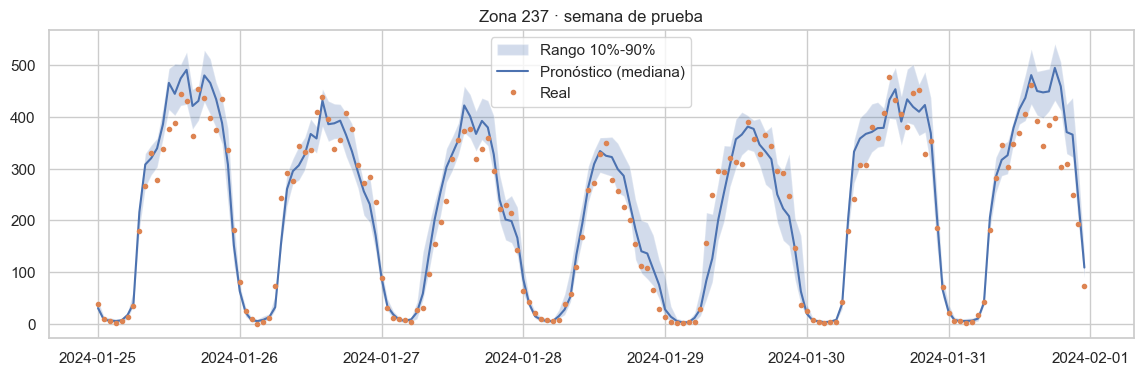

In [78]:
# Gráfico: una zona de la semana de prueba con su banda
zdemo = zonas_pronostico[50]
m = prueba["PULocationID"] == zdemo
fig, ax = plt.subplots(figsize=(14, 4))
horas = prueba.loc[m, "hora"]
ax.fill_between(horas, pred_prueba[m.to_numpy(), 0], pred_prueba[m.to_numpy(), 8],
                alpha=.25, label="Rango 10%-90%")
ax.plot(horas, pred_prueba[m.to_numpy(), 4], label="Pronóstico (mediana)")
ax.plot(horas, prueba.loc[m, "viajes"], ".", label="Real")
ax.set_title(f"Zona {zdemo} · semana de prueba"); ax.legend(); plt.show()

## 6. Parte 2 · Segmentación de zonas (K-Means + PCA)

Ahora cambiamos de pregunta: **¿qué tipos de zona hay?** Es aprendizaje *no supervisado*. Una fila por zona
(las ≥ 500 viajes), con variables que describen **cómo se usa** cada zona.

In [92]:
d = viajes[viajes["PULocationID"].isin(zonas_segmentar)].copy()
d["dow"] = d["tpep_pickup_datetime"].dt.dayofweek
d["h"]   = d["tpep_pickup_datetime"].dt.hour

# medianas de distancia y tarifa: primero descartar viajes con valor <= 0
dist_ok  = d[d["trip_distance"] > 0]
tarifa_ok = d[d["fare_amount"] > 0]

df_kmeans = pd.DataFrame(index=pd.Index(zonas_segmentar, name="PULocationID"))
df_kmeans["viajes_dia"]      = d.groupby("PULocationID").size() / 31.0 # Promedio de viajes por dia por zona
df_kmeans["dist_mediana"]    = dist_ok.groupby("PULocationID")["trip_distance"].median()
df_kmeans["tarifa_mediana"]  = tarifa_ok.groupby("PULocationID")["fare_amount"].median()
df_kmeans["propina_mediana"] = d.groupby("PULocationID")["tip_amount"].median()
df_kmeans["pct_finde"]  = d.assign(x=d["dow"] >= 5).groupby("PULocationID")["x"].mean() * 100
df_kmeans["pct_6a10"]   = d.assign(x=d["h"].between(6, 10)).groupby("PULocationID")["x"].mean() * 100
df_kmeans["pct_16a20"]  = d.assign(x=d["h"].between(16, 20)).groupby("PULocationID")["x"].mean() * 100
df_kmeans["pct_22a5"]   = d.assign(x=(d["h"] >= 22) | (d["h"] <= 5)).groupby("PULocationID")["x"].mean() * 100
df_kmeans = df_kmeans.fillna(df_kmeans.median())   # por si alguna zona quedó sin distancia/tarifa válida
df_kmeans.describe().round(2)

,viajes_dia,dist_mediana,tarifa_mediana,propina_mediana,pct_finde,pct_6a10,pct_16a20,pct_22a5
count,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
mean,944.90,3.41,19.78,1.81,26.39,22.09,26.40,20.11
std,1249.31,2.77,11.98,1.96,8.58,11.32,8.34,13.45
min,16.26,1.23,3.00,0.00,10.35,4.86,6.98,2.40
25%,30.06,1.61,12.10,0.00,21.46,13.58,20.99,11.66
50%,223.23,2.43,14.90,2.30,25.34,21.36,27.78,17.46
75%,1575.77,4.01,23.16,2.70,29.56,28.46,33.20,22.92
max,4685.16,17.41,70.00,10.00,54.93,58.25,42.82,72.07


K-Means usa distancias, así que **escalamos** con `StandardScaler`. Los viajes por día van en **escala
logarítmica** (hay zonas con 30 y otras con 4,500): sin el logaritmo, tres o cuatro zonas enormes
dominarían todo. Usamos `np.log1p` solo en esa columna y luego escalamos todo.

In [93]:
X = df_kmeans.copy()
X["viajes_dia"] = np.log1p(X["viajes_dia"])
escalador = StandardScaler()
Xs = escalador.fit_transform(X)
print("Matriz escalada:", Xs.shape)

Matriz escalada: (100, 8)


### ¿Cuántos grupos? Coeficiente de silueta para k = 2 … 7

La silueta mide qué tan separado está cada punto de su grupo vecino (de −1 a 1): más alta, mejor.
Pero la decisión también es **de negocio**: ¿cuántos segmentos puede atender el equipo con estrategias
distintas? Mostramos la silueta de k = 2 a 7 y elegimos con las dos cosas.

 k  silueta
 2    0.344
 3    0.381
 4    0.411
 5    0.364
 6    0.389
 7    0.377


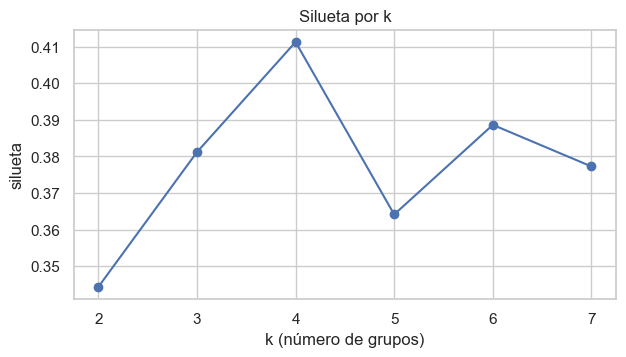

In [95]:
filas = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xs)
    filas.append({"k": k, "silueta": silhouette_score(Xs, km.labels_)})
tabla_sil = pd.DataFrame(filas)
print(tabla_sil.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(tabla_sil["k"], tabla_sil["silueta"], "o-")
ax.set_xlabel("k (número de grupos)"); ax.set_ylabel("silueta"); ax.set_title("Silueta por k")
plt.show()

En nuestros datos la silueta es más alta justo en **k = 4** (0.41), así que la métrica y el criterio de
negocio coinciden: cuatro grupos dan la mejor separación y, a la vez, una estrategia comercial accionable
(k = 2 sería demasiado grueso). Elegimos **k = 4**: centro, vida nocturna, aeropuertos y alrededores.

In [96]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Xs)
df_kmeans["grupo"] = km.labels_

# PCA a 2 componentes para poder dibujar las zonas
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Xs)
componentes = pca.transform(Xs)
df_kmeans["pca1"] = componentes[:, 0]
df_kmeans["pca2"] = componentes[:, 1]
var = pca.explained_variance_ratio_
print(f"PCA: componente 1 = {var[0]*100:.0f}%, componente 2 = {var[1]*100:.0f}%, "
      f"juntos = {var.sum()*100:.0f}% de la variación")

PCA: componente 1 = 39%, componente 2 = 27%, juntos = 66% de la variación


### Nombrar los grupos por su perfil (no por su número)

K-Means numera los grupos al azar: el grupo 0 de hoy puede ser el 2 mañana. Por eso no ponemos los
nombres a mano por número: los deducimos del perfil con reglas, para que el código funcione aunque la
numeración cambie.

- **Aeropuertos:** la mayor distancia mediana (viajes largos JFK/LGA/EWR).
- **Vida nocturna:** el mayor porcentaje de viajes de 22 a 5 h.
- **Manhattan central:** muchos viajes por día y distancias cortas.
- **Barrios periféricos:** el resto (pocos viajes por día).

In [98]:
perfil = df_kmeans.groupby("grupo")[["viajes_dia", "dist_mediana", "pct_22a5"]].median()

g_aero  = perfil["dist_mediana"].idxmax()
g_noche = perfil.drop(index=g_aero)["pct_22a5"].idxmax()
restantes = perfil.drop(index=[g_aero, g_noche])
g_centro = restantes["viajes_dia"].idxmax()
g_perif  = restantes["viajes_dia"].idxmin()

nombres_grupo = {g_aero: "Aeropuertos", g_noche: "Vida nocturna",
                 g_centro: "Manhattan central", g_perif: "Barrios periféricos"}
df_kmeans["nombre_grupo"] = df_kmeans["grupo"].map(nombres_grupo)
print(nombres_grupo)
df_kmeans.groupby("nombre_grupo").size()

{np.int32(2): 'Aeropuertos', np.int32(3): 'Vida nocturna', np.int32(1): 'Manhattan central', np.int32(0): 'Barrios periféricos'}


nombre_grupo
Aeropuertos             5
Barrios periféricos    39
Manhattan central      44
Vida nocturna          12
dtype: int64

In [101]:
# Perfil horario por zona (proporción de viajes en cada hora 0..23) -> mini-gráfico de la tabla de la app
perfil_h = (d.groupby(["PULocationID", "h"]).size()
            .unstack(fill_value=0))
perfil_h = perfil_h.div(perfil_h.sum(axis=1), axis=0)          # proporción por zona
perfil_h.columns = [f"h{int(c):02d}" for c in perfil_h.columns]
perfil_h = perfil_h.reindex(columns=[f"h{i:02d}" for i in range(24)], fill_value=0)
perfil_h

,h00,h01,h02,h03,h04,h05,h06,h07,h08,h09,h10,h11,h12,h13,h14,h15,h16,h17,h18,h19,h20,h21,h22,h23
PULocationID,,,,,,,,,,,,,,,,,,,,,,,,
4,0.109585,0.151345,0.125000,0.067825,0.020179,0.005605,0.013733,0.025224,0.039518,0.030830,0.025785,0.022141,0.020179,0.020179,0.022982,0.024383,0.021300,0.021300,0.026906,0.032511,0.027186,0.034193,0.039518,0.072590
7,0.018774,0.024848,0.020983,0.023192,0.039205,0.027609,0.048040,0.044727,0.069575,0.064053,0.059636,0.045279,0.054114,0.046383,0.054114,0.061292,0.060188,0.045831,0.038653,0.041414,0.028161,0.033131,0.019326,0.031474
10,0.028028,0.010010,0.004004,0.007007,0.004004,0.036036,0.068068,0.077077,0.054054,0.040040,0.028028,0.032032,0.033033,0.045045,0.061061,0.051051,0.095095,0.061061,0.028028,0.047047,0.046046,0.052052,0.055055,0.037037
12,0.005714,0.000000,0.001143,0.000000,0.001143,0.001143,0.000000,0.002286,0.017143,0.012571,0.030857,0.075429,0.110857,0.131429,0.141714,0.155429,0.153143,0.081143,0.025143,0.011429,0.018286,0.009143,0.010286,0.004571
13,0.005228,0.002708,0.001008,0.002078,0.002078,0.003464,0.008629,0.025194,0.043837,0.039239,0.041444,0.053851,0.058512,0.066826,0.070290,0.074636,0.078604,0.102538,0.108522,0.081376,0.057127,0.041318,0.020911,0.010581
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
256,0.118421,0.087719,0.066886,0.053728,0.055921,0.024123,0.012061,0.024123,0.037281,0.020833,0.023026,0.016447,0.016447,0.025219,0.023026,0.031798,0.024123,0.023026,0.037281,0.039474,0.042763,0.029605,0.072368,0.094298
260,0.025830,0.033210,0.023370,0.022140,0.019680,0.025830,0.047970,0.065191,0.105781,0.050431,0.046740,0.056581,0.038130,0.043050,0.059041,0.060271,0.059041,0.033210,0.024600,0.030750,0.027060,0.038130,0.030750,0.033210
261,0.014504,0.009850,0.005429,0.004266,0.003490,0.004266,0.005972,0.012022,0.020864,0.029473,0.036842,0.053983,0.066315,0.074226,0.081672,0.086946,0.085395,0.092376,0.094625,0.075855,0.050725,0.041883,0.027922,0.021097


## 7. Cruce Parte 1 × Parte 2: Limitaciones del modelo

Unimos el error del pronóstico (Parte 1) con el tipo de zona (Parte 2). Esto es lo que la ficha del
modelo mostrará: típicamente el error es mayor en **aeropuertos** (dependen de vuelos y retrasos que el
modelo no ve).

In [106]:
zona_grupo = df_kmeans["nombre_grupo"]
err = prueba.assign(abs_err=np.abs(real - p50))
err["tipo"] = err["PULocationID"].map(zona_grupo)
error_por_tipo = err.groupby("tipo")["abs_err"].mean().round(2)
print(error_por_tipo.to_string())

tipo
Aeropuertos            17.86
Barrios periféricos     2.50
Manhattan central      12.40
Vida nocturna           9.05


## 8 Archivos de la API

In [107]:
os.makedirs("api", exist_ok=True)
os.makedirs("app/data", exist_ok=True)

nombres_zona = pd.read_csv(ZONAS).set_index("LocationID")

info_modelo = {
    "variables": VARIABLES,
    "cuantiles": CUANTILES,
    "horizonte_horas": 24,
    "fechas": [d.strftime("%Y-%m-%d")
               for d in pd.date_range("2024-01-25", "2024-02-01")],
    "zonas": [{"id": int(z),
               "nombre": str(nombres_zona.loc[z, "Zone"]),
               "distrito": str(nombres_zona.loc[z, "Borough"])}
              for z in zonas_pronostico],
}
with open("api/info_modelo.json", "w", encoding="utf-8") as f:
    json.dump(info_modelo, f, ensure_ascii=False, indent=2)

modelo.save_model("api/modelo_pronostico.ubj")
print("Guardados: api/info_modelo.json y api/modelo_pronostico.ubj")

Guardados: api/info_modelo.json y api/modelo_pronostico.ubj


`demanda.parquet` son las filas del **25 de enero al 1 de febrero** con sus variables **ya calculadas**.
La API no recalcula lags: solo filtra por zona y fecha, predice y responde. Guardamos las columnas
numéricas y el `viajes` real (NaN en el 1 de feb); la API reconstruye la categoría `zona` desde
`PULocationID` para garantizar el mismo orden de categorías que en el entrenamiento.

In [109]:
cols_demanda = ["PULocationID", "hora", "viajes"] + num_vars   # num_vars = VARIABLES sin 'zona'
demanda = serie[(serie["hora"] >= "2024-01-25") &
                (serie["hora"] <= "2024-02-01 23:00")][cols_demanda].copy()
demanda.to_parquet("api/demanda.parquet", index=False)
print("Guardado: api/demanda.parquet  ->", demanda.shape)
demanda

Guardado: api/demanda.parquet  -> (11136, 12)


,PULocationID,hora,viajes,hora_dia,dia_semana,feriado,lag_24,lag_48,lag_168,lag_167,lag_169,media_dia_ant
576,4,2024-01-25 00:00:00,4.0,0,3,0,2.0,3.0,2.0,1.0,5.0,2.333333
577,4,2024-01-25 01:00:00,2.0,1,3,0,3.0,2.0,1.0,0.0,2.0,2.333333
578,4,2024-01-25 02:00:00,0.0,2,3,0,0.0,5.0,0.0,0.0,1.0,2.333333
579,4,2024-01-25 03:00:00,0.0,3,3,0,0.0,0.0,0.0,0.0,0.0,2.333333
580,4,2024-01-25 04:00:00,0.0,4,3,0,0.0,0.0,0.0,0.0,0.0,2.333333
...,...,...,...,...,...,...,...,...,...,...,...,...
44539,263,2024-02-01 19:00:00,NaN,19,3,0,106.0,115.0,84.0,110.0,140.0,80.833333
44540,263,2024-02-01 20:00:00,NaN,20,3,0,104.0,99.0,110.0,104.0,84.0,80.833333
44541,263,2024-02-01 21:00:00,NaN,21,3,0,92.0,96.0,104.0,85.0,110.0,80.833333
44542,263,2024-02-01 22:00:00,NaN,22,3,0,80.0,63.0,85.0,66.0,104.0,80.833333


### 8.2 Archivos de la app

In [110]:
# Tabla de zonas segmentadas (una fila por zona) + perfil horario + nombre/distrito
seg = df_kmeans.reset_index().merge(perfil_h.reset_index(), on="PULocationID", how="left")
seg["nombre"]   = seg["PULocationID"].map(nombres_zona["Zone"])
seg["distrito"] = seg["PULocationID"].map(nombres_zona["Borough"])
seg = seg.rename(columns={"PULocationID": "zona_id"})
seg.to_csv("app/data/zonas_segmentadas.csv", index=False)
print("Guardado: app/data/zonas_segmentadas.csv ->", seg.shape)

Guardado: app/data/zonas_segmentadas.csv -> (100, 39)


In [111]:
# Todas las cifras de la ficha del modelo
metricas = {
    "mae_modelo":  round(float(mae_modelo), 2),
    "mae_semanal": round(float(mae_semanal), 2),
    "mae_diario":  round(float(mae_diario), 2),
    "mejora_vs_semanal_pct": round(float((mae_semanal - mae_modelo) / mae_semanal * 100), 1),
    "cobertura_80": round(float(cobertura_80 * 100), 1),
    "cobertura_zona_min": round(float(cob_zona.min() * 100), 0),
    "cobertura_zona_max": round(float(cob_zona.max() * 100), 0),
    "n_horas_prueba": int(len(prueba)),
    "n_zonas_pronostico": int(len(zonas_pronostico)),
    "n_zonas_segmentar": int(len(zonas_segmentar)),
    "n_grupos": int(K),
    "pca_var_pct": round(float(var.sum() * 100), 0),
    "error_vs_reglas": {
        "Igual que ayer": round(float(mae_diario), 2),
        "Igual que hace una semana": round(float(mae_semanal), 2),
        "Modelo (mediana)": round(float(mae_modelo), 2),
    },
    "error_por_tipo_zona": {k: round(float(v), 2) for k, v in error_por_tipo.items()},
    "silueta_por_k": {int(r.k): round(float(r.silueta), 3) for r in tabla_sil.itertuples()},
    "entrenamiento": "1-24 de enero de 2024",
    "prueba": "25-31 de enero de 2024",
    "horizonte": "24 horas (pronóstico del día anterior)",
    "modelo": f"XGBoost · {len(CUANTILES)} cuantiles",
}
with open("app/data/metricas_modelo.json", "w", encoding="utf-8") as f:
    json.dump(metricas, f, ensure_ascii=False, indent=2)
print(json.dumps(metricas, ensure_ascii=False, indent=2))

{
  "mae_modelo": 11.54,
  "mae_semanal": 11.88,
  "mae_diario": 21.29,
  "mejora_vs_semanal_pct": 2.9,
  "cobertura_80": 81.8,
  "cobertura_zona_min": 63.0,
  "cobertura_zona_max": 91.0,
  "n_horas_prueba": 9744,
  "n_zonas_pronostico": 58,
  "n_zonas_segmentar": 100,
  "n_grupos": 4,
  "pca_var_pct": 66.0,
  "error_vs_reglas": {
    "Igual que ayer": 21.29,
    "Igual que hace una semana": 11.88,
    "Modelo (mediana)": 11.54
  },
  "error_por_tipo_zona": {
    "Aeropuertos": 17.86,
    "Barrios periféricos": 2.5,
    "Manhattan central": 12.4,
    "Vida nocturna": 9.05
  },
  "silueta_por_k": {
    "2": 0.344,
    "3": 0.381,
    "4": 0.411,
    "5": 0.364,
    "6": 0.389,
    "7": 0.377
  },
  "entrenamiento": "1-24 de enero de 2024",
  "prueba": "25-31 de enero de 2024",
  "horizonte": "24 horas (pronóstico del día anterior)",
  "modelo": "XGBoost · 9 cuantiles"
}


In [112]:
import os
tam = os.path.getsize("api/modelo_pronostico.ubj") / 1e6
print(f"Tamaño del modelo: {tam:.1f} MB", "  (OK para GitHub)" if tam < 25 else "  (>25 MB: baja n_estimators o max_depth)")

Tamaño del modelo: 17.7 MB   (OK para GitHub)
